# 08 — Fine-tuning Chronos-2, and the final benchmark

Two things left: adapt the model itself to our series, then compare everything once, on the test window.

**LoRA in one paragraph.** Full fine-tuning updates the 120M weights, which a laptop cannot afford. LoRA
(*low-rank adaptation*) freezes them and learns, for the attention matrices and the output layer, a small
correction of rank 8: the product of two thin matrices. A few hundred thousand trainable parameters instead of
120 million, which is what makes a CPU run possible. Chronos-2 has it built in (`fit(finetune_mode="lora")`).

**Protocol: the fine-tune never sees what it is scored on.** For each origin:
- training windows are cut at random in the history up to *origin − 28 days*;
- the 28 days just before the origin are a validation target, scored every 100 steps; the best checkpoint is
  kept (the same idea as the early stopping of the XGBoost baseline);
- the forecast window itself is never used.

The validation-window model chooses the configuration; the test-window model is a new fine-tune with the same
configuration on the longer history, as XGBoost was retrained for each window.

**Which context length to fine-tune at?** Notebook 07 found the best context for days 1–7 and for days 8–28.
We fine-tune at each, and since nothing forces a model to forecast with the context length it was tuned at,
we also try the other pairings.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import tempfile
import time
from datetime import timedelta
from importlib.metadata import version
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from m5_chronos2.data import ARTIFACTS_DIR, HORIZON, roster_name
from m5_chronos2.evaluation import actuals, make_windows
from m5_chronos2.metrics import METRICS, compare, join_truth, score
from m5_chronos2.chronos2 import (
    cached,
    checkpoint_dir,
    experiment_path,
    finetune,
    finetune_inputs,
    forecast,
    history,
    stitch,
)
from m5_chronos2.plots import MODEL_COLORS, MUTED_TEXT_COLOR, index_plot, plot_by_bucket, plot_fan, use_blog_style

use_blog_style()

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42
NAME = roster_name(SAMPLE_SIZE, SEED)
from m5_chronos2.chronos2 import resolve_device
DEVICE = resolve_device()   # cpu on the laptop, cuda on the tower

NUM_STEPS = 1000          # training steps per fine-tune
LEARNING_RATE = 1e-5      # the library suggests about 1e-5 for LoRA
BATCH_SIZE = 32           # series per training step
TIMING_STEPS = 20         # short run used to estimate the cost (section 1)
SELECTION_METRIC = "WQL"  # same rule as notebook 07

choice = json.loads((ARTIFACTS_DIR / f"context_choice_{NAME}.json").read_text())
EARLY_CONTEXT, LATE_CONTEXT = choice["early_context"], choice["late_context"]
EARLY_LAST_DAY = choice["early_last_day"]
FINETUNE_CONTEXTS = sorted({LATE_CONTEXT, EARLY_CONTEXT}, key=lambda length: length != LATE_CONTEXT)  # late first
PREDICT_CONTEXTS = sorted({EARLY_CONTEXT, LATE_CONTEXT})
print(f"From notebook 07: days 1-{EARLY_LAST_DAY} -> context {EARLY_CONTEXT}, days {EARLY_LAST_DAY + 1}-28 -> context {LATE_CONTEXT}")
print(f"Fine-tune at {FINETUNE_CONTEXTS}, forecast with {PREDICT_CONTEXTS}")

From notebook 07: days 1-7 -> context 1099, days 8-28 -> context 1829
Fine-tune at [1829, 1099], forecast with [1099, 1829]


In [3]:
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
truth = actuals(sales)
eval_roster = pl.read_parquet(ARTIFACTS_DIR / f"eval_roster_{NAME}.parquet")
windows = make_windows()
VALIDATION_ORIGIN, TEST_ORIGIN = windows["origin"].to_list()
validation_roster = eval_roster.filter(pl.col("role") == "validation")
series_ids = sales["id"].unique().sort().to_list()
PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Can this run on a laptop?

First the environment: LoRA needs the `peft` package. Without it, Chronos-2 does not fail: it warns and
falls back to *full* fine-tuning, which is a different experiment (and far heavier). `finetune` refuses to
start in that case.

Then a short timed run (`TIMING_STEPS` steps at the longest fine-tuning context, no validation) to estimate
the cost of the whole plan before launching it.

In [4]:
import torch

for package in ["chronos-forecasting", "torch", "transformers", "peft"]:
    print(f"{package:22s} {version(package)}")
print(f"device: {DEVICE}, CPU threads used by torch: {torch.get_num_threads()}")

train_inputs, validation_inputs = finetune_inputs(sales, VALIDATION_ORIGIN, series_ids)
print(f"{len(train_inputs)} training series (history up to {VALIDATION_ORIGIN - timedelta(days=HORIZON)}), "
      f"{len(validation_inputs)} validation series (up to {VALIDATION_ORIGIN})")

chronos-forecasting    2.3.2
torch                  2.2.2
transformers           4.57.6
peft                   0.21.2
device: cpu, CPU threads used by torch: 2
500 training series (history up to 2016-02-28), 500 validation series (up to 2016-03-27)


In [5]:
with tempfile.TemporaryDirectory() as scratch:
    start = time.time()
    finetune(train_inputs, None, context_length=max(FINETUNE_CONTEXTS), output_dir=Path(scratch) / "timing",
             num_steps=TIMING_STEPS, learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, device=DEVICE)
    seconds_per_step = (time.time() - start) / TIMING_STEPS   # includes the set-up: a slight over-estimate

start = time.time()
forecast(history(sales, VALIDATION_ORIGIN), VALIDATION_ORIGIN, context_length=max(FINETUNE_CONTEXTS), device=DEVICE)
seconds_per_evaluation = time.time() - start               # one pass over the validation series

hours_per_run = (NUM_STEPS * seconds_per_step + (NUM_STEPS // 100) * seconds_per_evaluation) / 3600
n_runs = 2 * len(FINETUNE_CONTEXTS)   # at most: every context at the validation origin, then again at the test origin
print(f"{seconds_per_step:.1f} s per training step, {seconds_per_evaluation:.0f} s per evaluation")
print(f"Estimate: {hours_per_run:.1f} h per fine-tune, at most {n_runs} fine-tunes -> up to {n_runs * hours_per_run:.1f} h")

/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  fine-tune on cpu, dtype torch.float32, batch 32 = 32 x 1 accumulated


Could not estimate the number of tokens of the input, floating-point operations will not be computed


Step,Training Loss


KeyboardInterrupt: 

**How to read the estimate.** Each fine-tune is cached on disk, so the plan can be spread over several
sessions (re-running a cell skips every checkpoint already saved). As a rule of thumb, a few hours per run is
workable on a laptop left on overnight; beyond that, or to try more configurations (learning rate, number of
steps, LoRA rank), move the fine-tuning to a free GPU notebook: see the appendix at the end.

## 2. Fine-tune, validation origin

In [6]:
def checkpoint_for(origin, finetune_context):
    return checkpoint_dir(NAME, origin, finetune_context, NUM_STEPS, LEARNING_RATE, BATCH_SIZE)


def run_finetunes(origin, contexts, inputs):
    for finetune_context in contexts:
        start = time.time()
        print(f"origin {origin}, fine-tuning at context {finetune_context}")
        finetune(*inputs, context_length=finetune_context, output_dir=checkpoint_for(origin, finetune_context),
                 num_steps=NUM_STEPS, learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, device=DEVICE)
        print(f"  {(time.time() - start) / 60:.0f} min")


run_finetunes(VALIDATION_ORIGIN, FINETUNE_CONTEXTS, (train_inputs, validation_inputs))

origin 2016-03-27, fine-tuning at context 1829
  checkpoint found, not retrained: origin2016-03-27_ctx1829_steps1000_lr1e-05_bs32
  0 min
origin 2016-03-27, fine-tuning at context 1099
  checkpoint found, not retrained: origin2016-03-27_ctx1099_steps1000_lr1e-05_bs32
  0 min


Did the model learn anything? The trainer logs the training loss and, every 100 steps, the loss on the
validation target (the 28 days before the origin). The kept checkpoint is the one with the lowest validation loss.

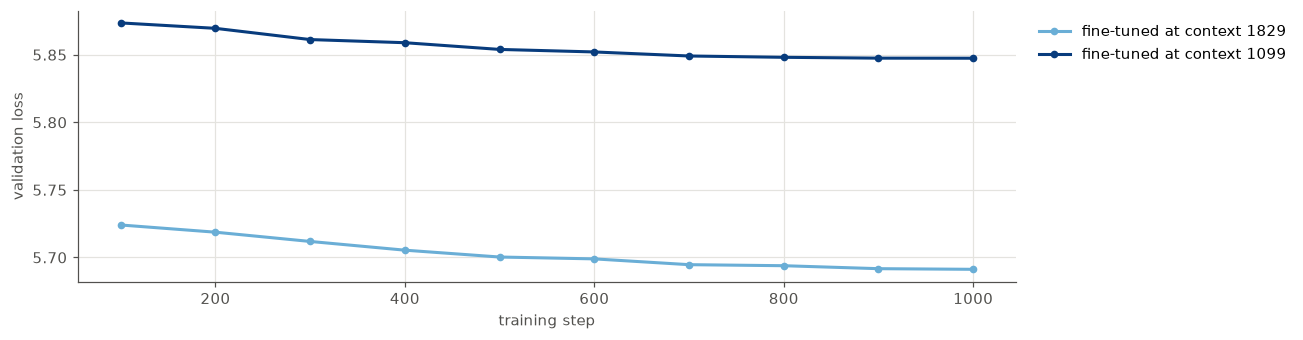

In [7]:
def training_log(output_dir):
    states = sorted(Path(output_dir).glob("checkpoint-*/trainer_state.json"),
                    key=lambda path: int(path.parent.name.split("-")[1]))
    if not states:
        return None
    log = json.loads(states[-1].read_text())["log_history"]
    return pl.DataFrame([row for row in log if "eval_loss" in row]).select("step", "eval_loss")


fig, ax = plt.subplots(figsize=(11, 3.2))
ramp = plt.get_cmap("Blues")
for finetune_context, shade in zip(FINETUNE_CONTEXTS, np.linspace(0.5, 0.95, len(FINETUNE_CONTEXTS))):
    log = training_log(checkpoint_for(VALIDATION_ORIGIN, finetune_context))
    if log is not None:
        ax.plot(log["step"].to_numpy(), log["eval_loss"].to_numpy(), color=ramp(shade), marker="o",
                markersize=4, label=f"fine-tuned at context {finetune_context}")
ax.set_xlabel("training step")
ax.set_ylabel("validation loss")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 3. Which pairing wins where? (validation window)

Candidates: the vanilla model and every fine-tuned model, each forecasting with every context length of
notebook 07's choice. Each forecast is cached; the vanilla ones are the files of notebook 07.

In [8]:
def vanilla_at(length, origin):
    name = f"context_{length}" if origin == VALIDATION_ORIGIN else f"context_{length}_origin{origin}"
    return cached(experiment_path(name, NAME), lambda: forecast(
        history(sales, origin), origin, context_length=int(length), device=DEVICE))


def finetuned_at(finetune_context, length, origin):
    checkpoint = checkpoint_for(origin, finetune_context) / "finetuned-ckpt"
    assert checkpoint.exists(), f"no checkpoint for origin {origin}, context {finetune_context}: run the fine-tune first"
    name = f"lora_ctx{finetune_context}_steps{NUM_STEPS}_lr{LEARNING_RATE:g}_bs{BATCH_SIZE}_context_{length}_origin{origin}"
    return cached(experiment_path(name, NAME), lambda: forecast(
        history(sales, origin), origin, context_length=int(length), model_path=checkpoint, device=DEVICE))


def label(config):
    kind, finetune_context, length = config
    return f"vanilla, context {length}" if kind == "vanilla" else f"LoRA@{finetune_context}, context {length}"


def predictions_for(config, origin):
    kind, finetune_context, length = config
    return vanilla_at(length, origin) if kind == "vanilla" else finetuned_at(finetune_context, length, origin)


configs = [("vanilla", None, length) for length in PREDICT_CONTEXTS] + [
    ("finetuned", finetune_context, length) for finetune_context in FINETUNE_CONTEXTS for length in PREDICT_CONTEXTS
]
validation_scored = {label(c): join_truth(predictions_for(c, VALIDATION_ORIGIN), truth, validation_roster) for c in configs}

In [9]:
segment = pl.when(pl.col("horizon") <= EARLY_LAST_DAY).then(pl.lit(f"days 01-{EARLY_LAST_DAY:02d}")).otherwise(pl.lit(f"days {EARLY_LAST_DAY + 1:02d}-28"))
by_segment = compare({name: table.with_columns(segment.alias("segment")) for name, table in validation_scored.items()}, by="segment")
by_segment.select("model", "segment", "WQL", "WMAPE", "MAE").pivot(on="segment", index="model", values=["WQL", "WMAPE"])

model,WQL_days 01-07,WQL_days 08-28,WMAPE_days 01-07,WMAPE_days 08-28
str,f64,f64,f64,f64
"""vanilla, context 1099""",0.545072,0.562732,68.871931,71.232458
"""vanilla, context 1829""",0.545644,0.562194,68.897745,71.085181
"""LoRA@1829, context 1099""",0.544574,0.562055,68.950583,71.147126
"""LoRA@1829, context 1829""",0.544656,0.561352,68.87579,70.916788
"""LoRA@1099, context 1099""",0.544502,0.561754,68.933236,71.101063
"""LoRA@1099, context 1829""",0.544528,0.561132,68.862199,70.898533


By horizon bucket, relative to the vanilla model at the early context length.

In [10]:
compare(validation_scored, by="horizon_bucket", reference=label(("vanilla", None, EARLY_CONTEXT))).select(
    "model", "horizon_bucket", "WQL_change_%", "WMAPE_change_%"
).pivot(on="horizon_bucket", index="model", values="WQL_change_%")

model,days 01-07,days 08-14,days 15-21,days 22-28
str,f64,f64,f64,f64
"""vanilla, context 1099""",0.0,0.0,0.0,0.0
"""vanilla, context 1829""",0.105001,-0.289624,-0.358636,0.350699
"""LoRA@1829, context 1099""",-0.091407,-0.105536,-0.213855,-0.043315
"""LoRA@1829, context 1829""",-0.076232,-0.371135,-0.448831,0.076583
"""LoRA@1099, context 1099""",-0.104611,-0.123656,-0.261508,-0.137217
"""LoRA@1099, context 1829""",-0.099714,-0.367717,-0.471972,-0.019339


The rule of notebook 07, applied to all candidates: per segment, the lowest WQL.

In [11]:
best_label = {
    name: part.sort(SELECTION_METRIC)["model"][0]
    for (name,), part in by_segment.group_by("segment", maintain_order=True)
}
config_of = {label(c): c for c in configs}
segment_names = sorted(best_label)
EARLY_CONFIG, LATE_CONFIG = config_of[best_label[segment_names[0]]], config_of[best_label[segment_names[1]]]
print(f"{segment_names[0]}: {label(EARLY_CONFIG)}")
print(f"{segment_names[1]}: {label(LATE_CONFIG)}")

days 01-07: LoRA@1099, context 1099
days 08-28: LoRA@1099, context 1829


## 4. The final model

The two chosen configurations, stitched at day 7, for both windows. For the test window, any fine-tuned
model is fine-tuned again at the test origin with the same configuration (history up to the test origin; the
28 days before it as validation target).

In [12]:
needed = sorted({c[1] for c in (EARLY_CONFIG, LATE_CONFIG) if c[0] == "finetuned"})
if needed:
    run_finetunes(TEST_ORIGIN, needed, finetune_inputs(sales, TEST_ORIGIN, series_ids))

best = pl.concat([
    stitch(predictions_for(EARLY_CONFIG, origin), predictions_for(LATE_CONFIG, origin), EARLY_LAST_DAY)
    for origin in windows["origin"].to_list()
])
assert best.height == len(series_ids) * HORIZON * windows.height
best.write_parquet(PREDICTIONS_DIR / f"chronos2_best_{NAME}.parquet")

(ARTIFACTS_DIR / f"chronos2_best_config_{NAME}.json").write_text(json.dumps({
    "early_days": [1, EARLY_LAST_DAY], "early": label(EARLY_CONFIG),
    "late_days": [EARLY_LAST_DAY + 1, HORIZON], "late": label(LATE_CONFIG),
    "lora": {"num_steps": NUM_STEPS, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE, "rank": 8},
}, indent=2))
print("Saved chronos2_best")

origin 2016-04-24, fine-tuning at context 1099
  checkpoint found, not retrained: origin2016-04-24_ctx1099_steps1000_lr1e-05_bs32
  0 min
Saved chronos2_best


## 5. Final benchmark, test window

The test window (2016-04-25 to 2016-05-22) was used for no decision anywhere in notebooks 05 to 08.

In [13]:
model_names = ["zero", "seasonal_naive", "moving_average_28d", "xgboost_btrotta", "chronos2_vanilla", "chronos2_best"]
scored = {
    model: join_truth(pl.read_parquet(PREDICTIONS_DIR / f"{model}_{NAME}.parquet"), truth, eval_roster)
    .join(windows.select("origin", "role"), on="origin")
    for model in model_names
}
test = {model: table.filter(pl.col("role") == "test") for model, table in scored.items()}
compare(test).select(["model", "n_series"] + METRICS).sort("WMAPE")

model,n_series,MAE,WMAPE,P90,WQL,RQL
str,u32,f64,f64,f64,f64,f64
"""chronos2_vanilla""",485,0.869666,70.010461,2.101769,0.550018,23.878201
"""chronos2_best""",485,0.869933,70.031977,2.117783,0.548748,22.918286
"""xgboost_btrotta""",485,0.948566,76.362099,2.060481,0.763621,36.824994
"""moving_average_28d""",485,0.963718,77.58187,2.178571,0.775819,37.974645
"""seasonal_naive""",485,1.176215,94.688482,3.0,0.946885,46.04778
"""zero""",485,1.242194,100.0,3.0,1.0,20.0


Gains, in % of error removed (positive = better). Against XGBoost, only the point-forecast metrics are
compared (its WQL is just WMAPE / 100).

In [14]:
def gains(model, reference, metrics):
    table = compare({model: test[model], reference: test[reference]}, reference=reference).filter(pl.col("model") == model)
    return table.select(
        pl.lit(f"{model} vs {reference}").alias("comparison"),
        *[(-pl.col(f"{metric}_change_%")).alias(f"{metric} gain %") for metric in metrics],
    )

pl.concat([
    gains("chronos2_vanilla", "xgboost_btrotta", ["MAE", "WMAPE", "P90"]),
    gains("chronos2_best", "xgboost_btrotta", ["MAE", "WMAPE", "P90"]),
    gains("chronos2_best", "chronos2_vanilla", ["MAE", "WMAPE", "P90", "WQL"]),
], how="diagonal")

comparison,MAE gain %,WMAPE gain %,P90 gain %,WQL gain %
str,f64,f64,f64,f64
"""chronos2_vanilla vs xgboost_bt…",8.317789,8.317789,-2.003834,null
"""chronos2_best vs xgboost_btrot…",8.289612,8.289612,-2.781019,null
"""chronos2_best vs chronos2_vani…",-0.030733,-0.030733,-0.761917,0.23096


/var/folders/k4/pclq47c50r78wfcdxrrbr27c0000gn/T/ipykernel_53352/796061160.py:2: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


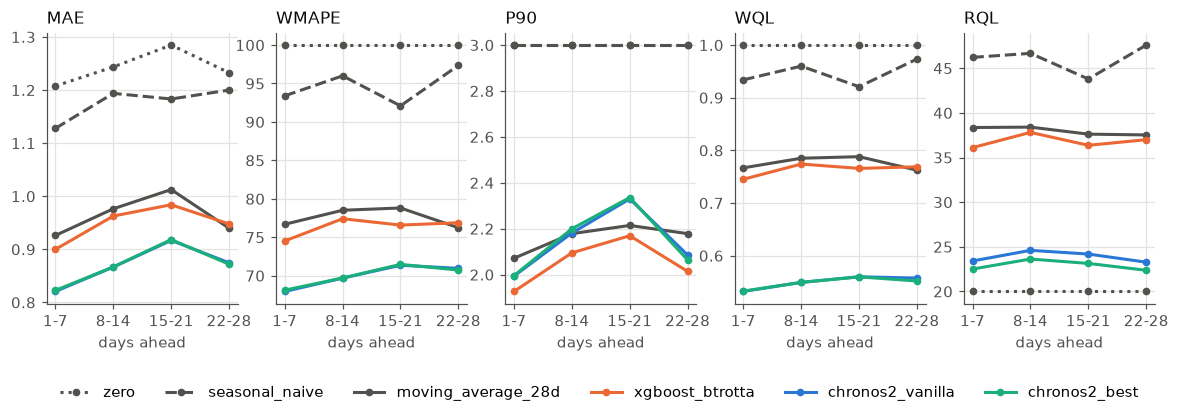

In [15]:
fig, axes = plot_by_bucket(compare(test, by="horizon_bucket"), METRICS)
fig.tight_layout()
plt.show()

Series by series, test window: the final Chronos-2 against XGBoost (WMAPE).

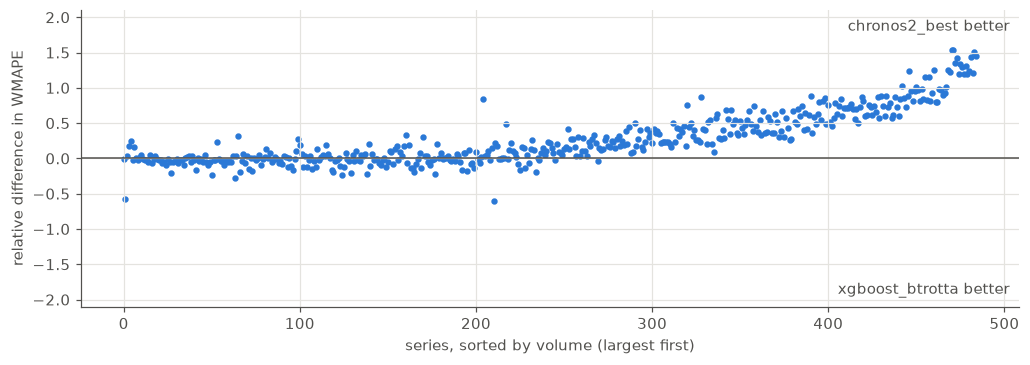

chronos2_best has the lower WMAPE on 72% of series


In [16]:
def per_series(model, metric):
    return score(test[model], by="id").select("id", pl.col(metric).alias(f"{metric}_{model}"))

volume = test["chronos2_best"].group_by("id").agg(pl.col("y").sum().alias("volume"))
per_series_wmape = per_series("xgboost_btrotta", "WMAPE").join(per_series("chronos2_best", "WMAPE"), on="id").join(volume, on="id")

fig, ax = plt.subplots(figsize=(11, 3.5))
share = index_plot(ax, per_series_wmape, "WMAPE", "xgboost_btrotta", "chronos2_best", order_by="volume")
plt.show()
print(f"chronos2_best has the lower WMAPE on {share:.0%} of series")

Four test series, picked by volume as in notebook 05. Aqua: the final Chronos-2 (median and bands); blue:
vanilla median; orange: XGBoost; dots: actual sales.

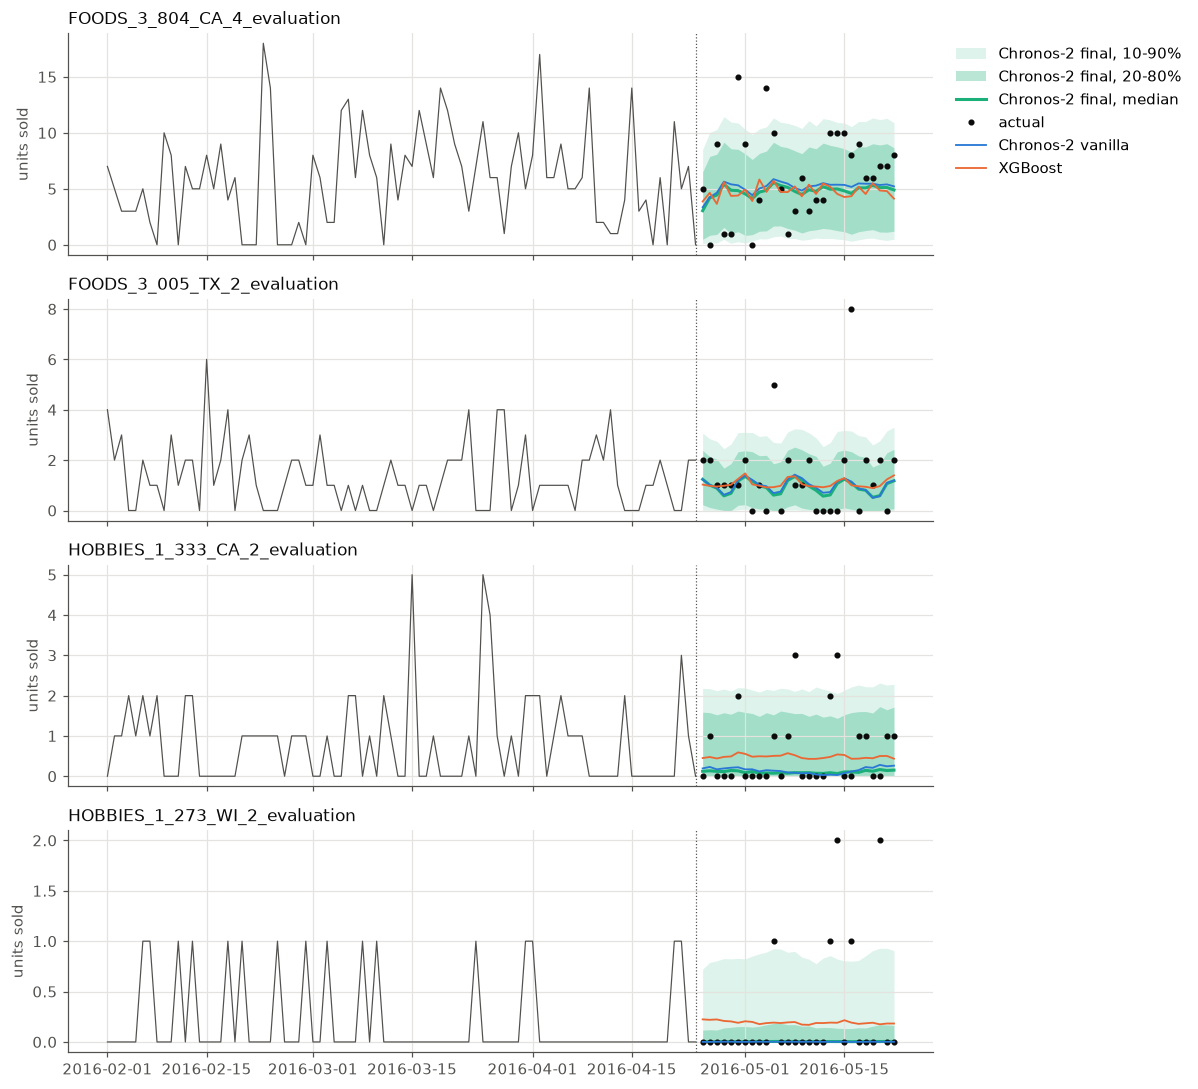

In [17]:
SHOW_DAYS = 84
ranked = volume.sort("volume")
example_ids = [ranked["id"][int(level * (ranked.height - 1))] for level in (0.98, 0.75, 0.5, 0.25)]
loaded = {model: pl.read_parquet(PREDICTIONS_DIR / f"{model}_{NAME}.parquet").filter(pl.col("origin") == TEST_ORIGIN)
          for model in ["xgboost_btrotta", "chronos2_vanilla", "chronos2_best"]}

fig, axes = plt.subplots(len(example_ids), 1, figsize=(11, 10), sharex=True)
for ax, series_id in zip(axes, example_ids):
    one = truth.filter(pl.col("id") == series_id)
    past = one.filter(pl.col("date") <= TEST_ORIGIN, pl.col("date") > TEST_ORIGIN - timedelta(days=SHOW_DAYS))
    actual = one.filter(pl.col("date") > TEST_ORIGIN, pl.col("date") <= TEST_ORIGIN + timedelta(days=HORIZON))
    pick = lambda model: loaded[model].filter(pl.col("id") == series_id)
    plot_fan(ax, past, pick("chronos2_best"), actual, color=MODEL_COLORS["chronos2_best"], label="Chronos-2 final")
    for model, name in [("chronos2_vanilla", "Chronos-2 vanilla"), ("xgboost_btrotta", "XGBoost")]:
        ax.plot(pick(model)["date"].to_numpy(), pick(model)["y_pred"].to_numpy(), color=MODEL_COLORS[model], linewidth=1.2, label=name)
    ax.axvline(TEST_ORIGIN, color=MUTED_TEXT_COLOR, linewidth=0.8, linestyle=":")
    ax.set_title(series_id, loc="left")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

## Notes

*Your observations here.*

---

## Appendix — running the fine-tuning on a free GPU (Kaggle)

Kaggle notebooks are a good fit: the M5 data is hosted there, and the free tier gives a T4 or P100 GPU
(about 30 GPU hours a week, sessions of up to 12 hours; the quota is shown in the account settings and
changes over time). Google Colab's free tier is similar but with no published quota.

Only notebook 08 needs to move, and it needs no raw CSV, only three files of `artifacts/`.

1. **Code**: push this repository to GitHub (`data/` and `artifacts/` are git-ignored).
2. **Artifacts**: upload `sales_flags_n500_seed42.parquet`, `eval_roster_n500_seed42.parquet` and
   `context_choice_n500_seed42.json` as a private Kaggle dataset (say `m5-chronos2-artifacts`).
3. **Notebook**: new Kaggle notebook, *Accelerator: GPU*, *Internet: on* (needed to install packages and
   download the model; it requires a verified phone number), add the dataset as input, then:
   ```
   !git clone https://github.com/<you>/m5-chronos2.git
   %cd m5-chronos2
   !pip install -q "chronos-forecasting[extras]>=2.3" polars
   !pip install -q -e . --no-deps        # --no-deps: keep Kaggle's CUDA torch, not the pinned Mac one
   !mkdir -p artifacts && cp /kaggle/input/m5-chronos2-artifacts/* artifacts/
   ```
4. Open `notebooks/08_chronos2_finetuning.ipynb`, set `DEVICE = "cuda"` (a larger `BATCH_SIZE` fits on a
   GPU), run sections 1 to 4. On CUDA, `finetune` keeps the library's fused optimizer.
5. **Bring the results back**: `!cd artifacts && zip -r /kaggle/working/finetuned.zip finetuned`, download it
   from the *Output* tab and unzip it into the laptop's `artifacts/`. Re-run the notebook on the laptop: every
   checkpoint is found and nothing is retrained (a checkpoint trained on GPU loads on CPU).

GPU and CPU runs are not bit-for-bit identical; compare configurations trained on the same hardware.